# **Multi-Dimensional Tensor Data Representation**

Tensors give machine-learning data a shape. We will build up from one value to batches of video clips and see what the axes describe in each example.

<!-- Source transcription: transcription/5.4.md -->
## **Tensors**

An n-dimensional array is a tensor: a data structure for numbers. Machine-learning libraries, including scikit-learn and TensorFlow, use arrays or tensors to store data.

### **0D Tensor: a scalar**

Values such as `(2)` and `(3)` are scalars. A scalar holds one value and has no axes, so its rank is 0. NumPy reports this with `ndim`; its shape is an empty tuple and its size is one.

In [ ]:
import numpy as np

scalar = np.array(4)
print("value:", scalar)
print("rank (ndim):", scalar.ndim)
print("shape:", scalar.shape)
print("size:", scalar.size)

value: 4
rank (ndim): 0
shape: ()
size: 1


Here, `ndim` is `0`, `shape` is `()`, and `size` is `1`: one number, with no axis.

### **1D Tensor: a vector**

A 1D tensor has one axis. The vector `[1, 2, 3, 4]` has rank 1 and shape `(4,)`: one axis containing four values.

In [ ]:
short_vector = np.array([1, 2, 3])
vector = np.array([1, 2, 3, 4])
print("[1, 2, 3] shape and size:", short_vector.shape, short_vector.size)
print("[1, 2, 3, 4] rank, shape, size:", vector.ndim, vector.shape, vector.size)

[1, 2, 3] shape and size: (3,) 3
[1, 2, 3, 4] rank, shape, size: 1 (4,) 4


The notes use “dimension” in two ways: a tensor’s dimension can mean its number of axes, while a mathematical vector’s dimension can mean its number of values. Here, those are 1 and 4, respectively.

Combining scalars forms a vector; stacking equal-length vectors forms a matrix. In NumPy, the brackets show these nested levels.

In [ ]:
two_vectors = np.array([[1, 2, 3], [4, 5, 6]])
print(two_vectors)
print("rank:", two_vectors.ndim, "shape:", two_vectors.shape)

[[1 2 3]
 [4 5 6]]
rank: 2 shape: (2, 3)


<!-- Source transcription: transcription/6.1.md -->
### **2D Tensor: a matrix**

A matrix is a collection of vectors. Its two axes describe rows and columns; this example has three rows and three values in each row.

In [ ]:
matrix = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
print(matrix)
print("rank (ndim):", matrix.ndim)
print("shape:", matrix.shape)
print("size:", matrix.size)

[[1 2 3]
 [4 5 6]
 [7 8 9]]
rank (ndim): 2
shape: (3, 3)
size: 9


### **Rank, shape, and size**

Rank is the number of axes. Shape gives the number of items along each axis, and size is the total number of values—the product of the shape entries.

If a tensor has rank $r$ and axis lengths $s_i$, its size is:

$$
\text{size} = \prod_{i=1}^{r} s_i
$$

In [ ]:
examples = [np.ones((3, 3)), np.ones((2, 3)), np.ones((4, 2))]
for array in examples:
    print(f"shape={array.shape}, rank={array.ndim}, size={array.size}")

shape=(3, 3), rank=2, size=9
shape=(2, 3), rank=2, size=6
shape=(4, 2), rank=2, size=8


The three examples contain 9, 6, and 8 values. The shape tells us how those values are arranged, while size counts them all.

### **3D, 4D, and 5D tensors**

A 3D tensor can be viewed as a stack of matrices; the handwritten example labels its shape `(4, 3, 3)`. A 4D tensor can group 3D tensors in a row, and a 5D tensor can arrange them in a matrix. The notes introduce tensors from 0D to 5D for machine-learning data.

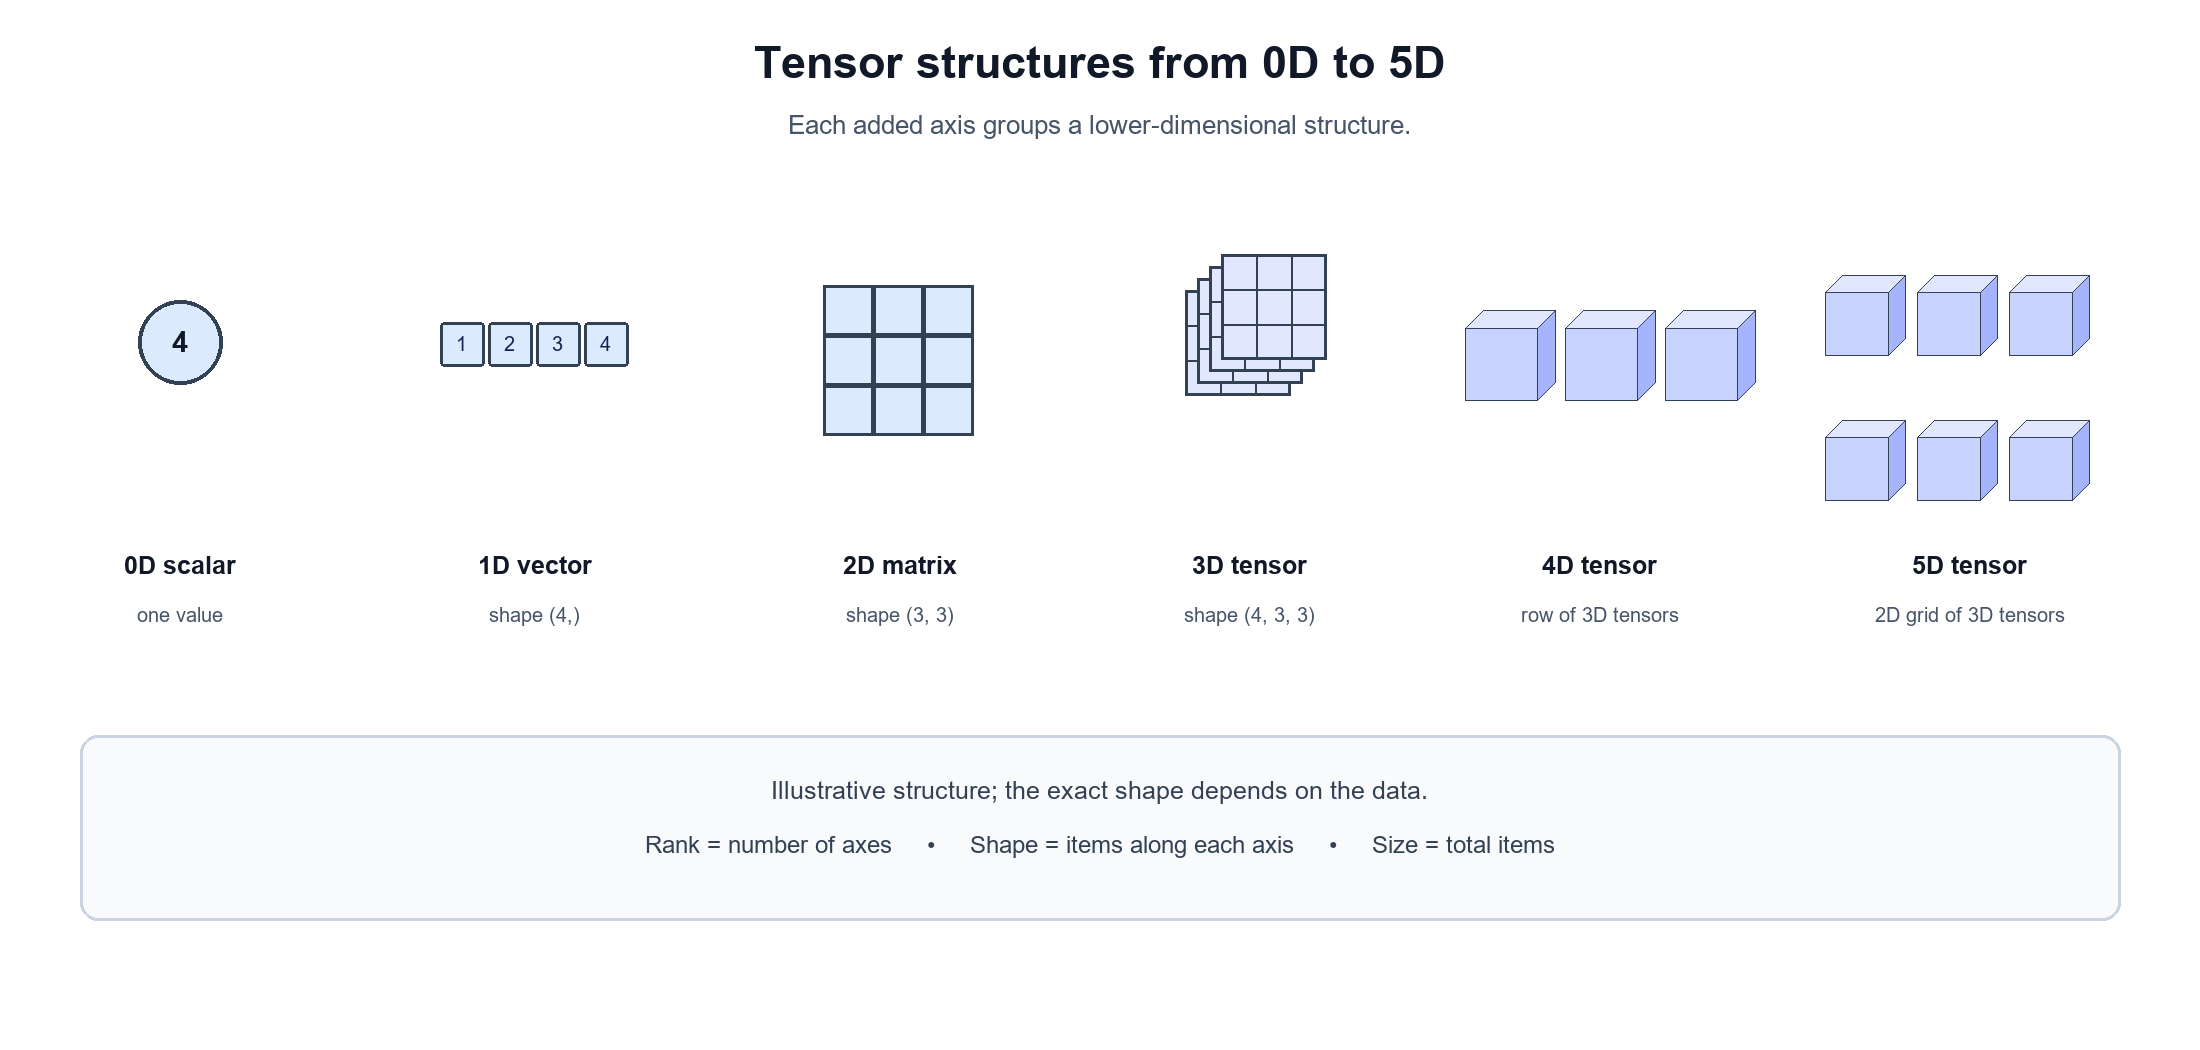

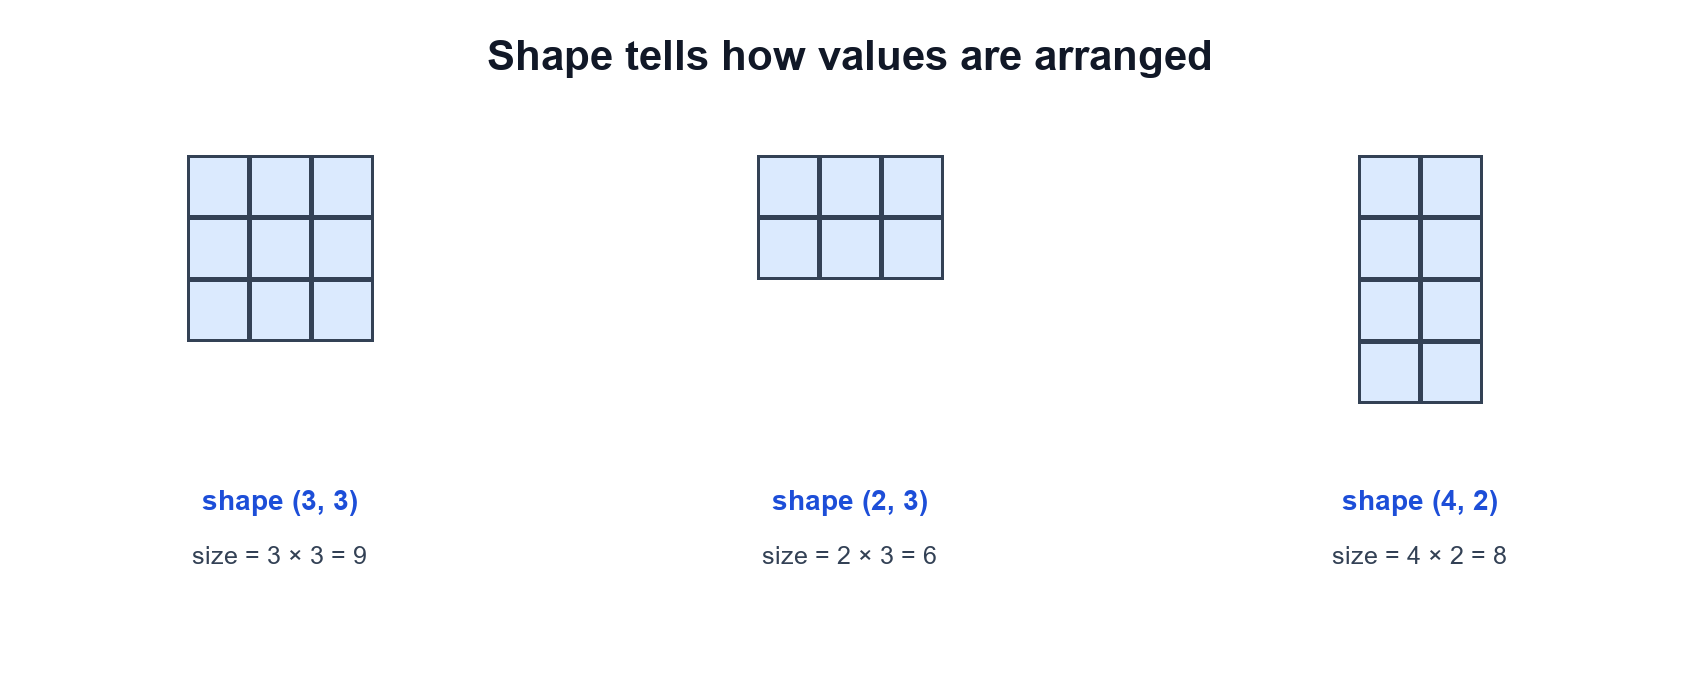

<!-- Source transcription: transcription/6.2.md -->
## **Student data as tensors**

For 10,000 students, the notes list CGPA, IQ, state, and placement. Each student's three input values form a vector; stacking the students makes a 2D feature tensor. The placement values form a separate 1D tensor, such as `[1, 1, 0, 1, 0, 1, 0, ...]`.

In the example, the state codes are written as `WP = 0` and `EP = 1`. The placement column is the target, so it stays separate from the three input columns.

In [ ]:
X = np.array([[8.1, 91, 0],
              [7.2, 81, 1]])
y = np.array([1, 1])

print("X:\n", X)
print("y:", y)
print("X shape:", X.shape, "rank:", X.ndim)
print("y shape:", y.shape, "rank:", y.ndim)
print("first student's feature vector:", X[0])
print("IQ values (column 1):", X[:, 1])

X:
 [[ 8.1 91.   0. ]
 [ 7.2 81.   1. ]]
y: [1 1]
X shape: (2, 3) rank: 2
y shape: (2,) rank: 1
first student's feature vector: [ 8.1 91.   0. ]
IQ values (column 1): [91. 81.]


`X[0]` selects one student's feature vector, and `X[:, 1]` selects the IQ column. The small code sample uses two rows; the handwritten example describes 10,000 students.

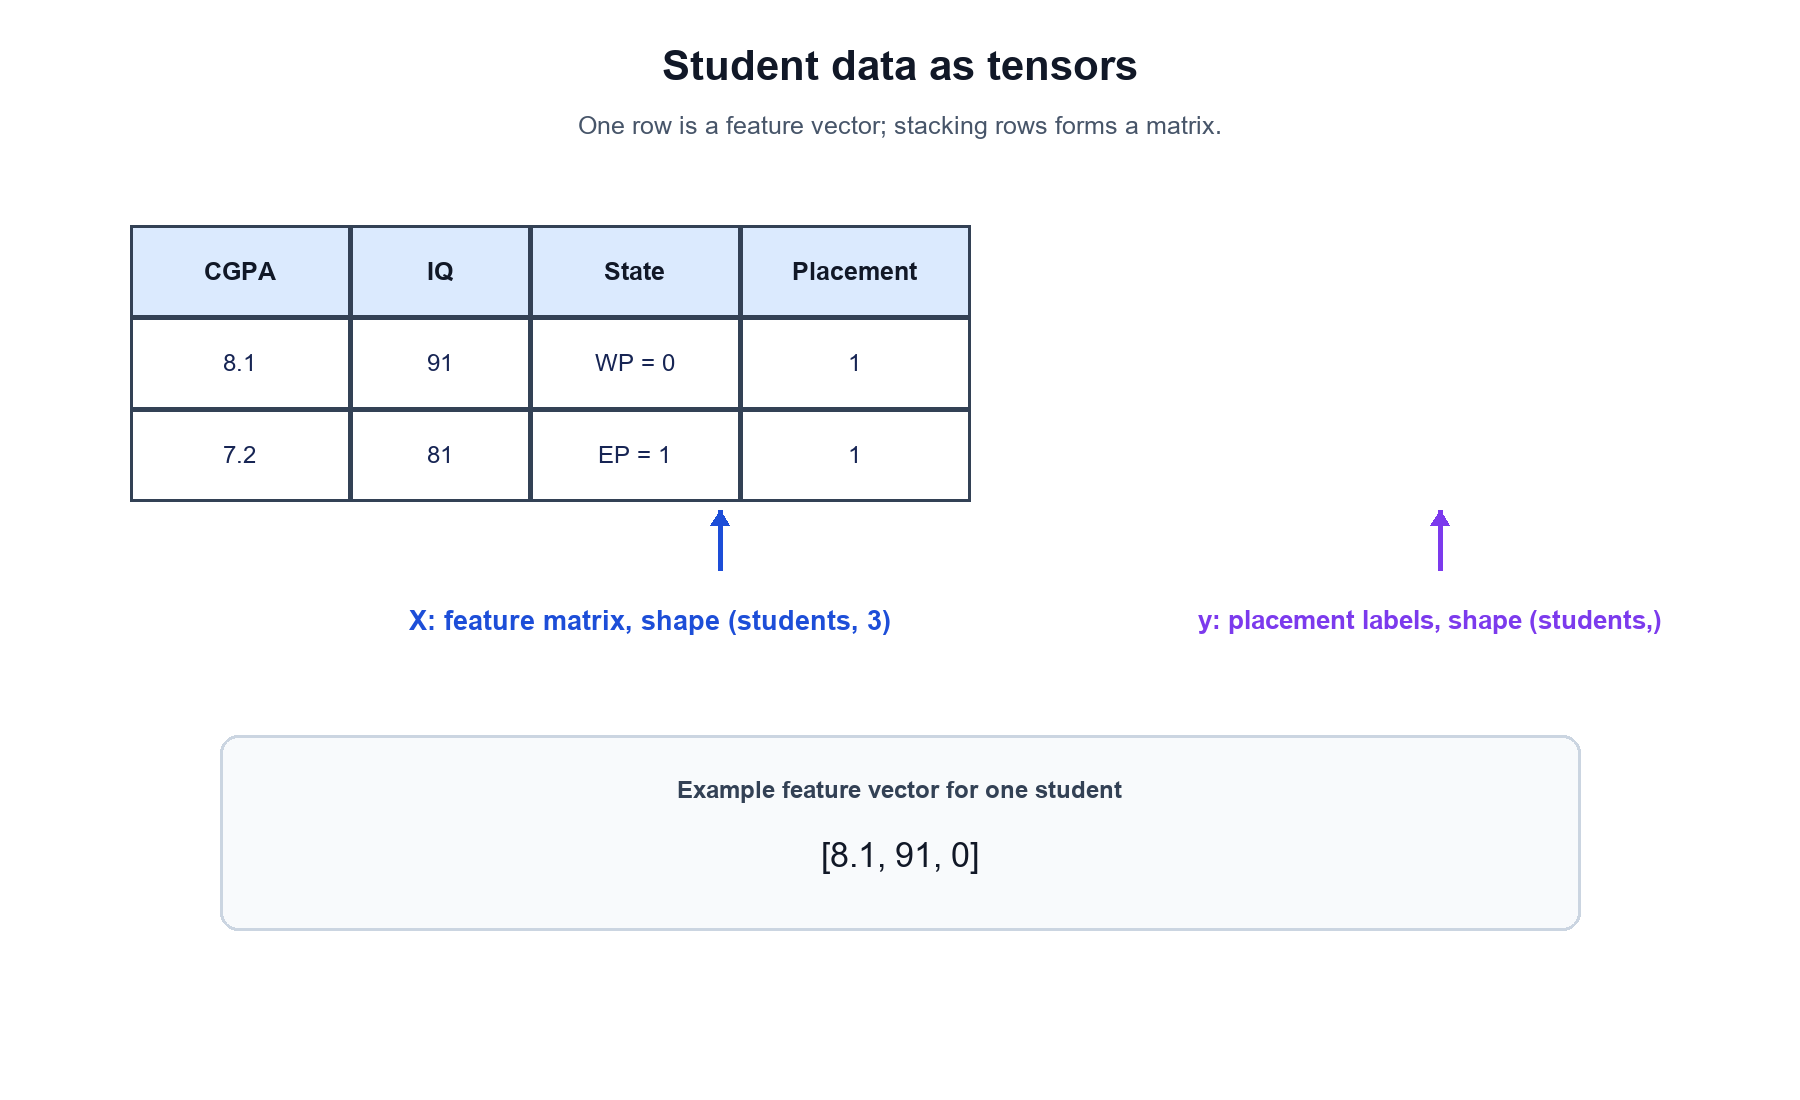

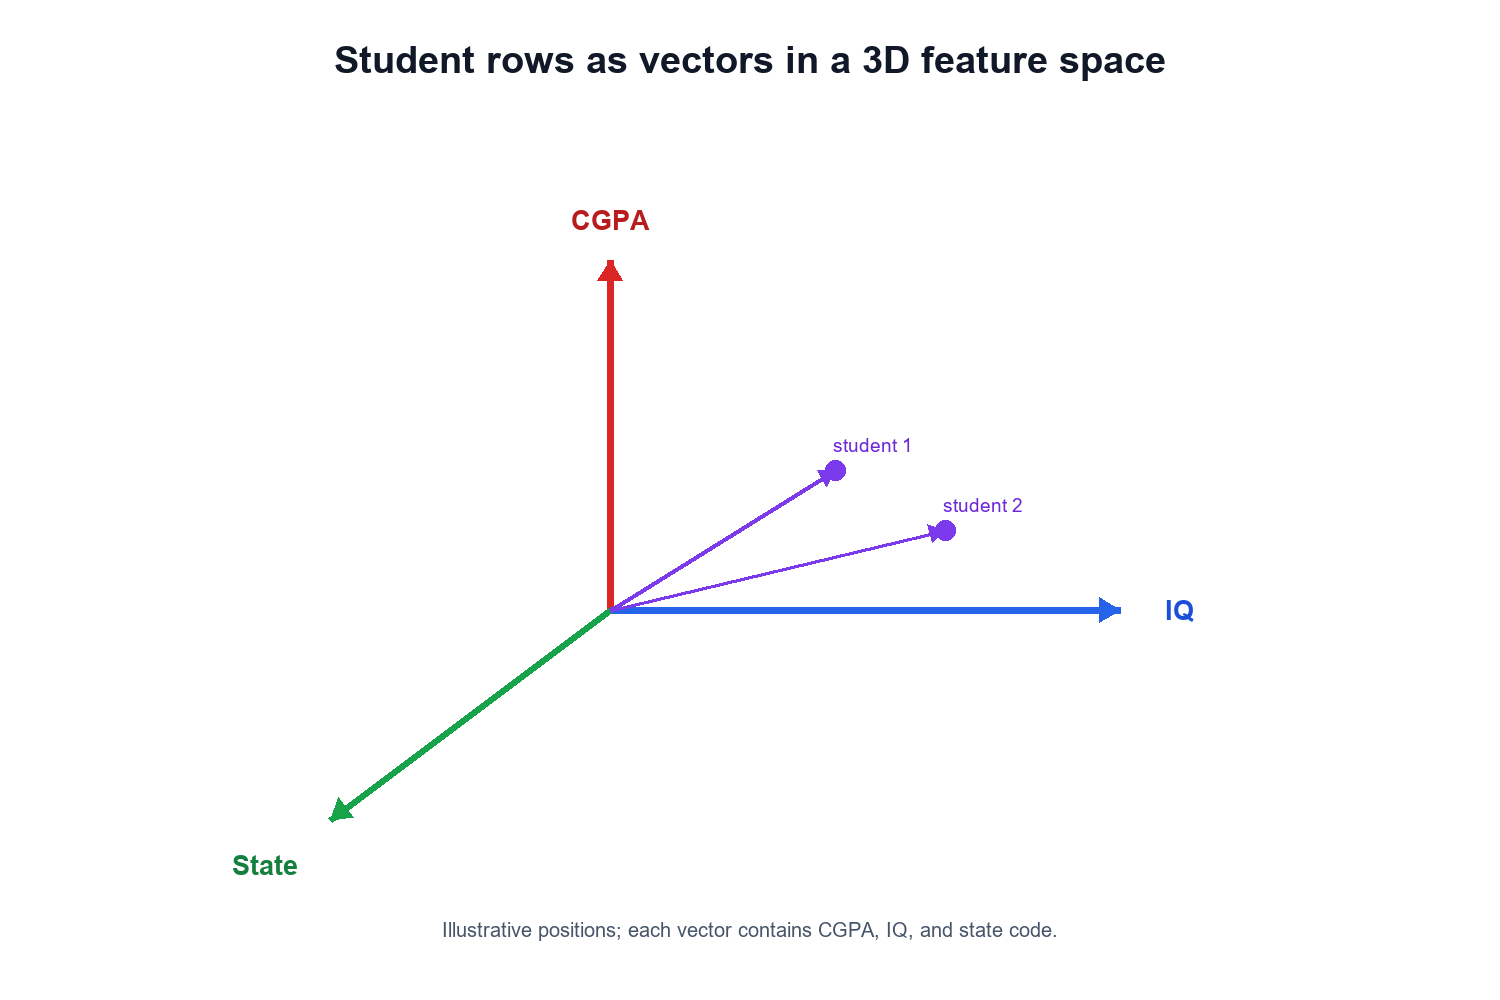

<!-- Source transcription: transcription/6.3.md -->
## **3D tensors: text and time-series data**

Vectorization converts text into numbers. In the handwritten example, we first choose the unique words, then represent each word with a four-value one-hot vector.

In [ ]:
vocabulary = ["Hi", "Faheem", "Ibraheem", "Sameer"]
one_hot = {word: np.eye(len(vocabulary), dtype=int)[i]
           for i, word in enumerate(vocabulary)}
sentences = [["Hi", "Faheem"],
             ["Hi", "Ibraheem"],
             ["Hi", "Sameer"]]
text_tensor = np.array([[one_hot[word] for word in sentence]
                        for sentence in sentences])
print("shape:", text_tensor.shape)
print("size:", text_tensor.size)
print("first sentence:\n", text_tensor[0])

shape: (3, 2, 4)
size: 24
first sentence:
 [[1 0 0 0]
 [0 1 0 0]]


The shape `(3, 2, 4)` means 3 sentences, 2 words per sentence, and 4 numbers per word. Its size is `3 × 2 × 4 = 24` values.

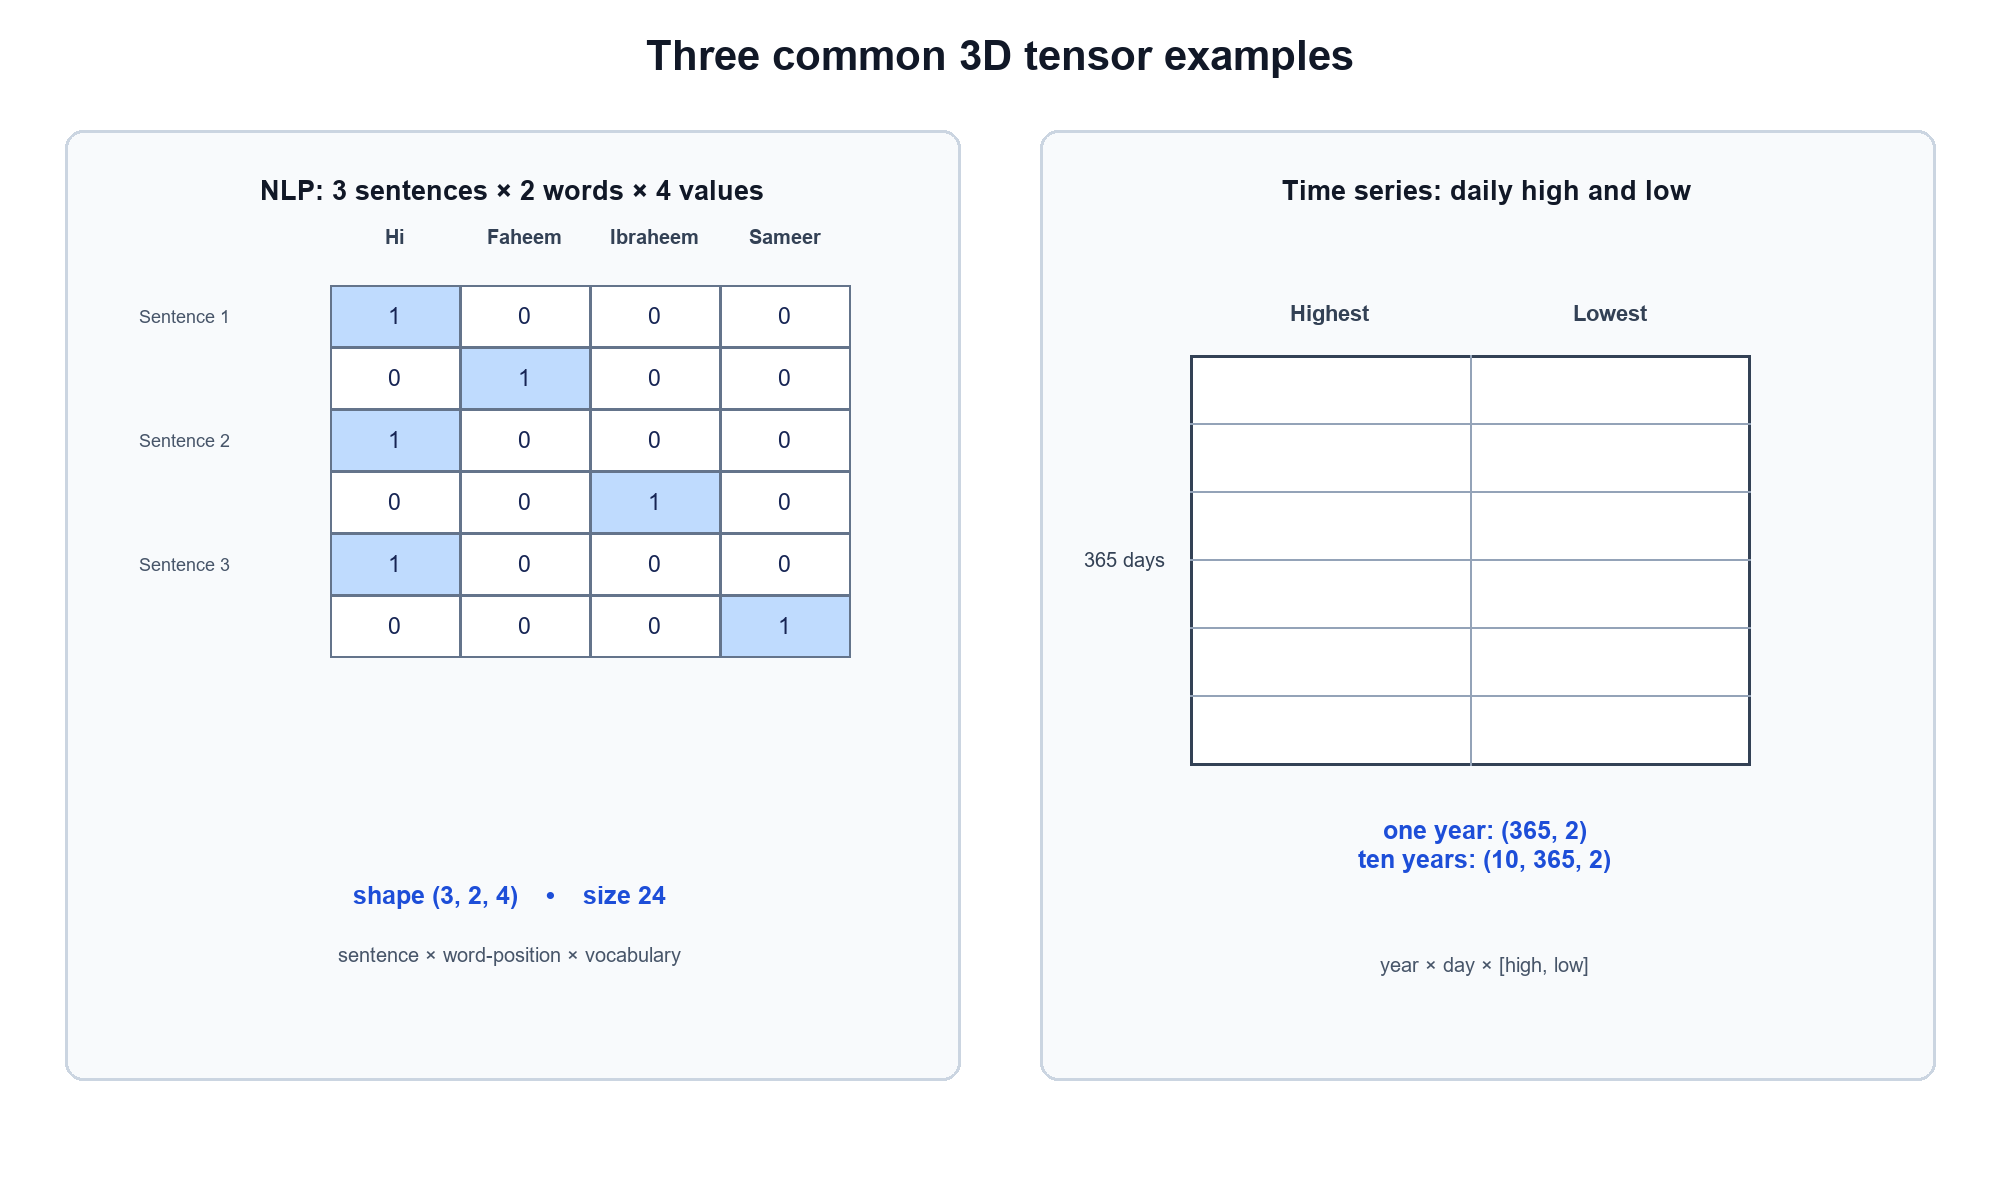

### **Time-series data**

Time-series data is collected over time; the notes use daily highest and lowest share prices as an example. One year has shape `(365, 2)`, and ten years can be arranged as `(10, 365, 2)`.

In [ ]:
year_shape = (365, 2)
ten_year_shape = (10, *year_shape)
market_data = np.zeros(ten_year_shape)  # Shape-only example, not real prices
print("one year (days, high/low):", year_shape)
print("ten years (years, days, high/low):", market_data.shape)
print("rank:", market_data.ndim, "size:", market_data.size)

one year (days, high/low): (365, 2)
ten years (years, days, high/low): (10, 365, 2)
rank: 3 size: 7300


The first axis now distinguishes the 10 years, the second tracks days, and the last holds the two prices. The zeros only create the shape; they are not market observations.

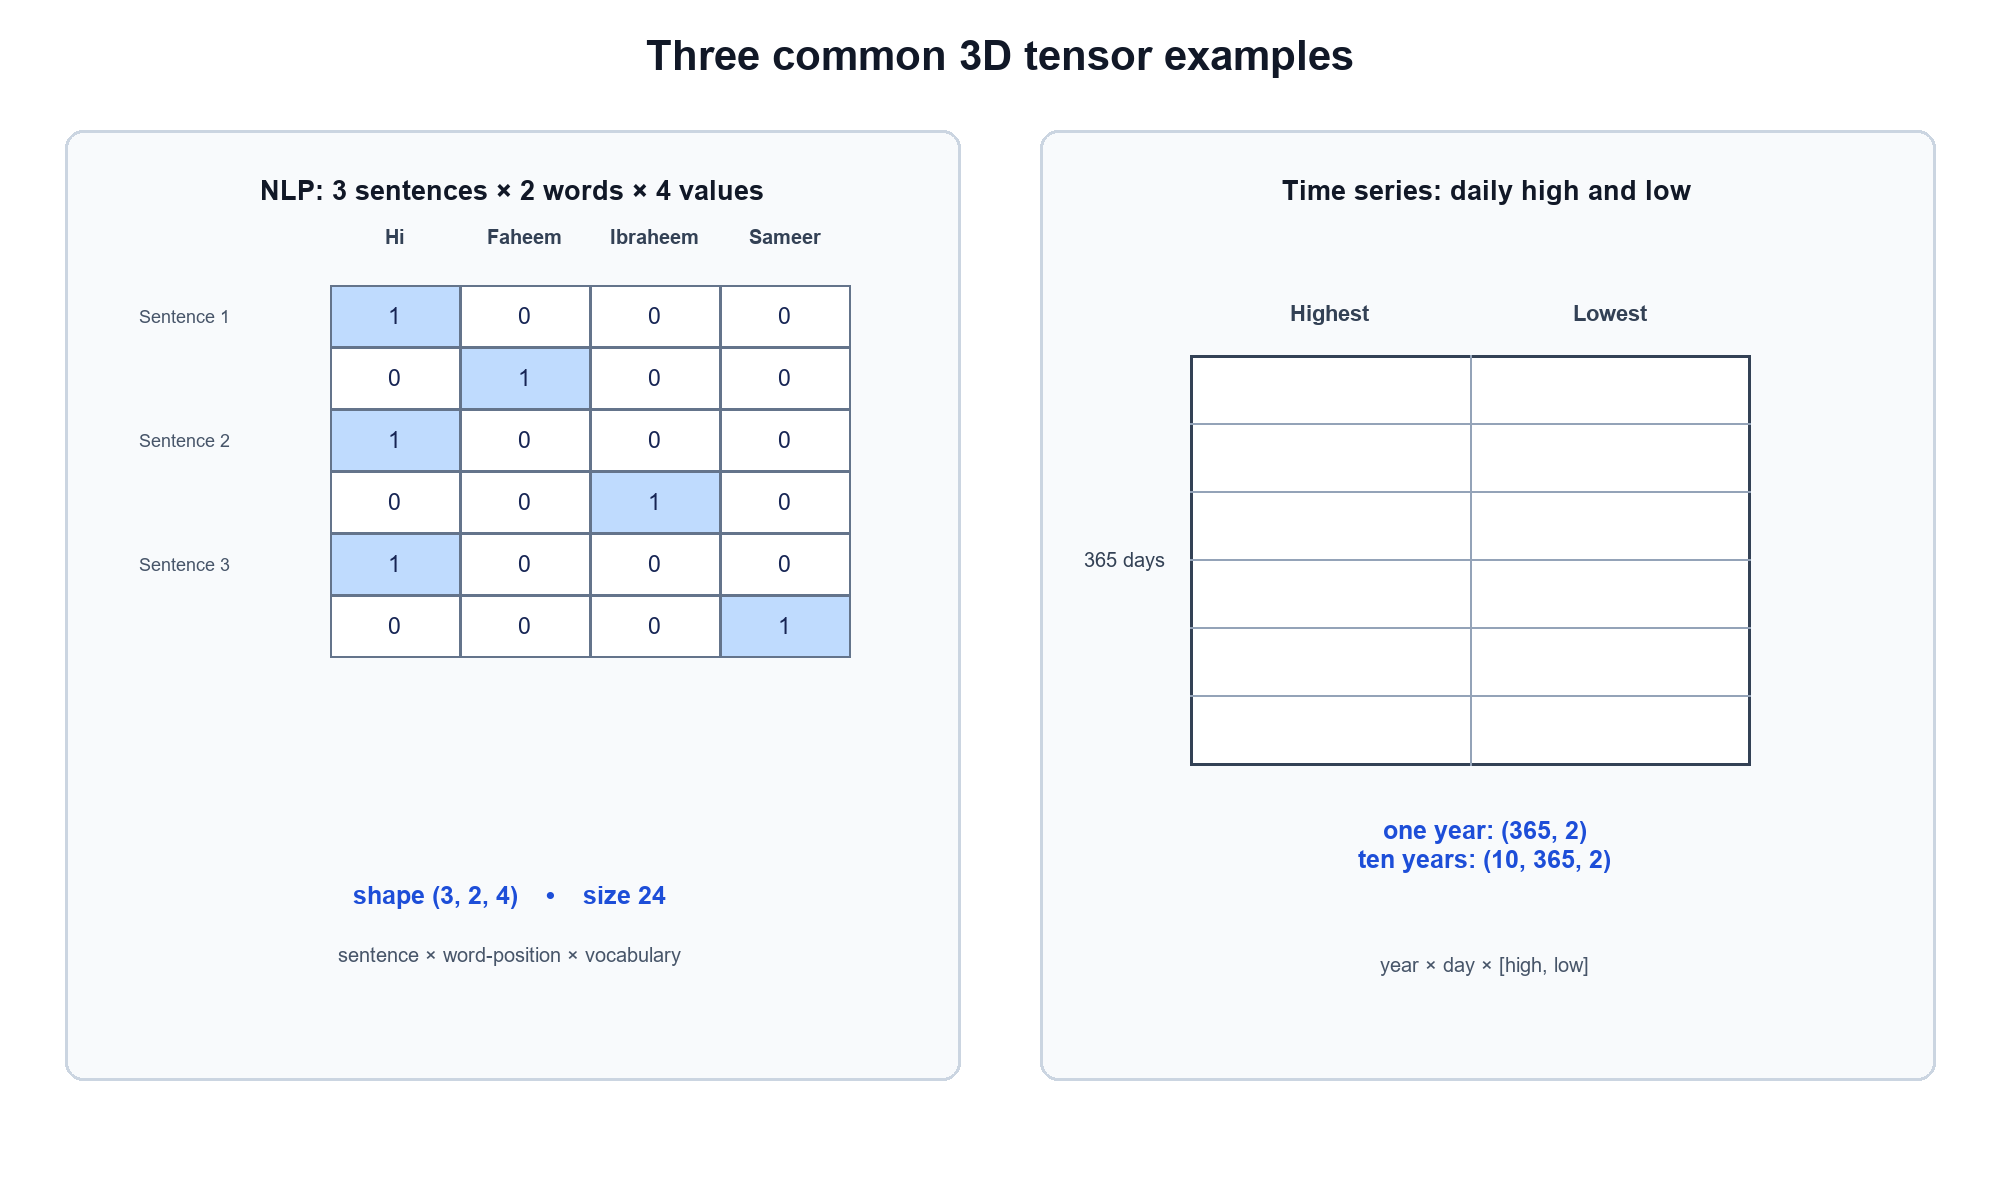

<!-- Source transcription: transcription/6.3.md -->
## **4D tensors: color images**

A color image can be stored as three color channels—red, green, and blue—with a height and width. The page uses one image of shape `(3, 1200, 800)` and a batch of 50 images with shape `(50, 3, 1200, 800)`.

This is a channel-first layout: batch, channel, height, width. Other software may place the channel axis last, so always check the shape convention being used.

In [ ]:
small_image = np.zeros((3, 4, 5), dtype=np.uint8)
small_batch = np.stack([small_image, small_image])
print("one channel-first image:", small_image.shape)
print("two-image batch:", small_batch.shape)
print("example 50-image batch:", (50, 3, 1200, 800))

one channel-first image: (3, 4, 5)
two-image batch: (2, 3, 4, 5)
example 50-image batch: (50, 3, 1200, 800)


Each pixel is represented by numerical values. These tiny zero-filled arrays show the axes without allocating the full 50-image example.

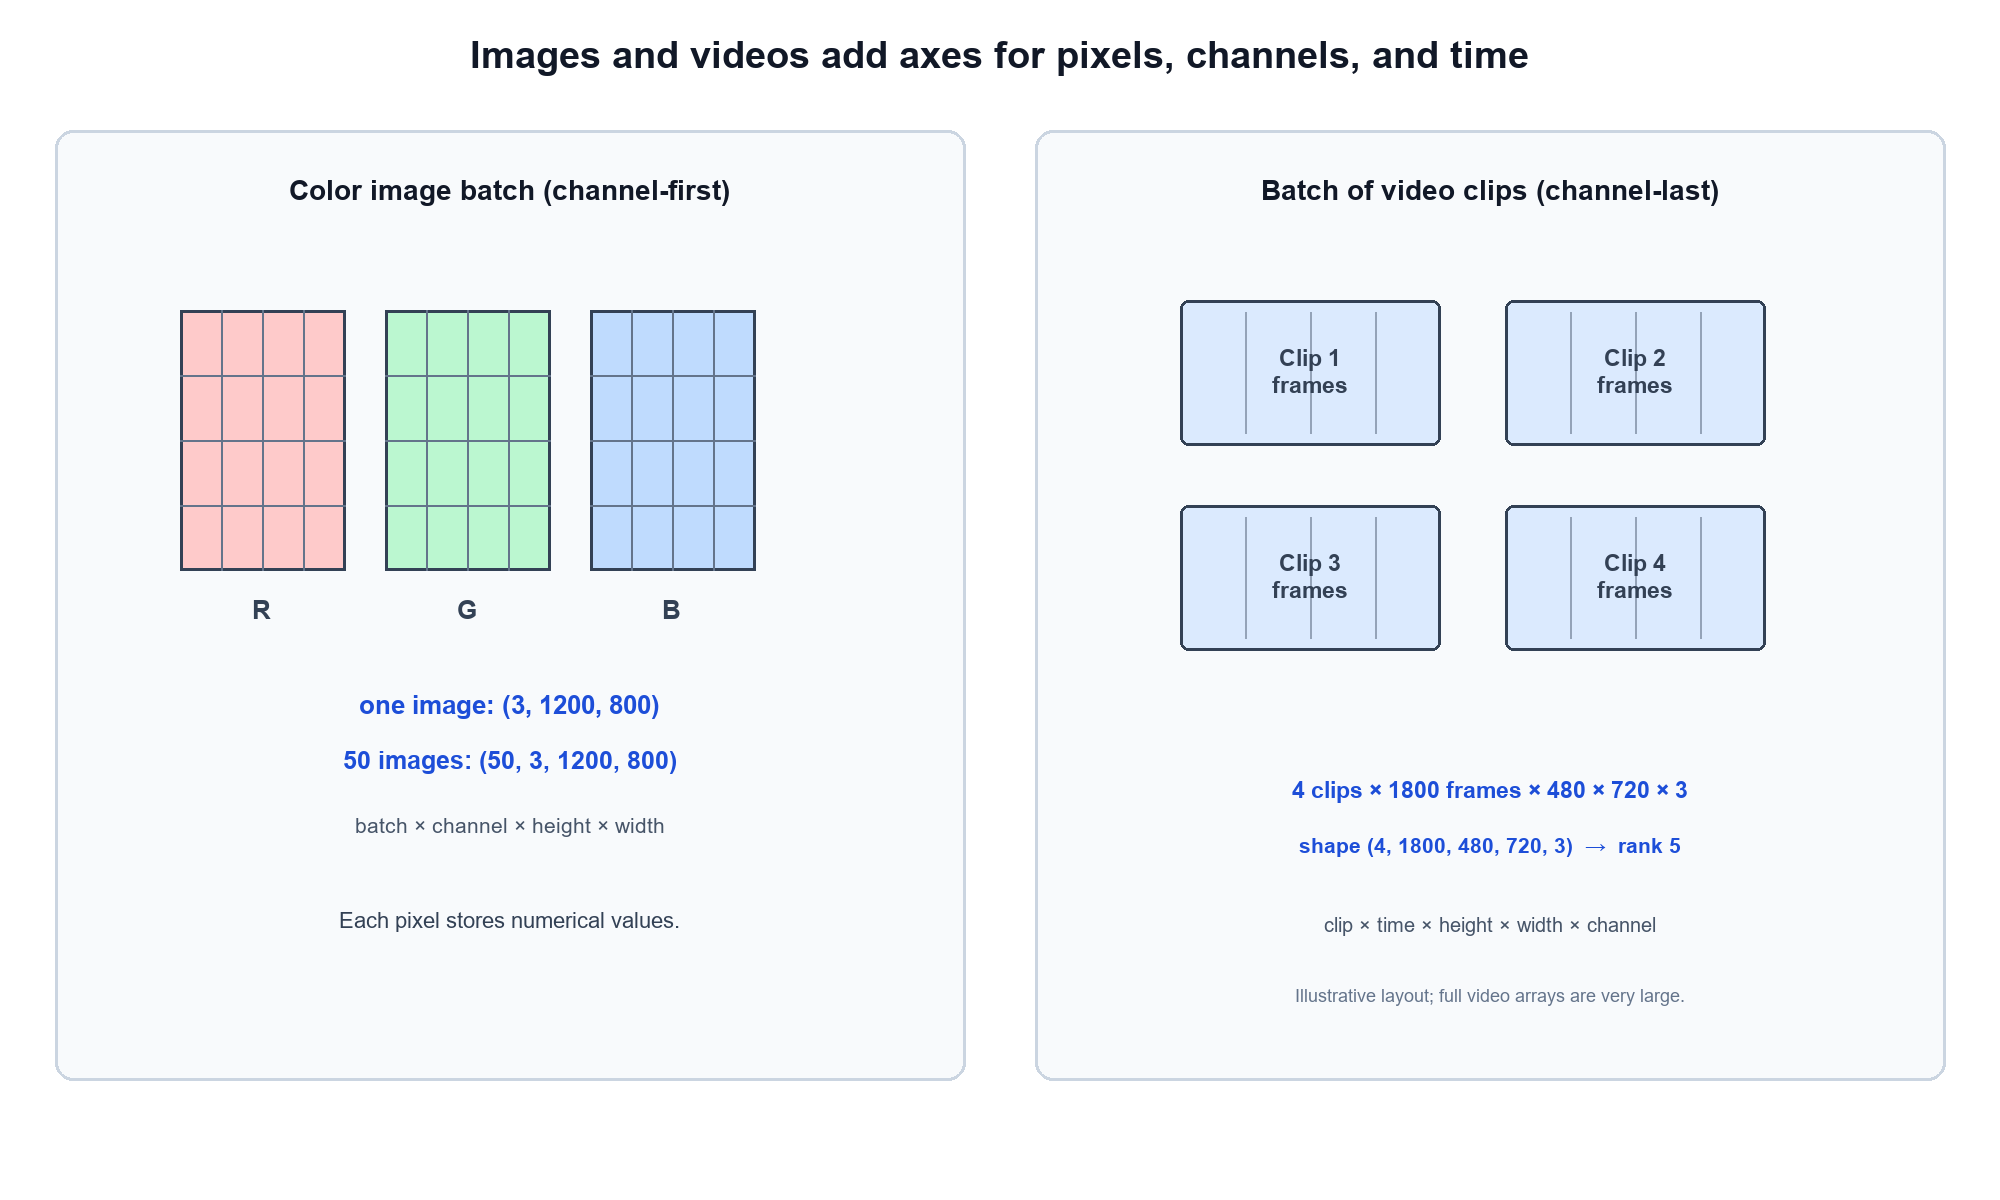

<!-- Source transcription: transcription/6.4.md -->
## **5D tensors: video clips**

A video is a sequence of frames, often described by frames per second (FPS). Following the page's example, a 60-second clip at 30 FPS has 1,800 frames; using 480 × 720 pixels and 3 color channels gives a 4D shape of `(1800, 480, 720, 3)`. Four clips add a batch axis, making a 5D tensor: `(4, 1800, 480, 720, 3)`.

The page says the eye can distinguish 12 images per second (persistence of vision). Treat this as the author's brief intuition for motion; here, the tensor point is that video adds a frame axis to image data. The page uses 480 x 720 as its example frame size; actual frame dimensions vary.

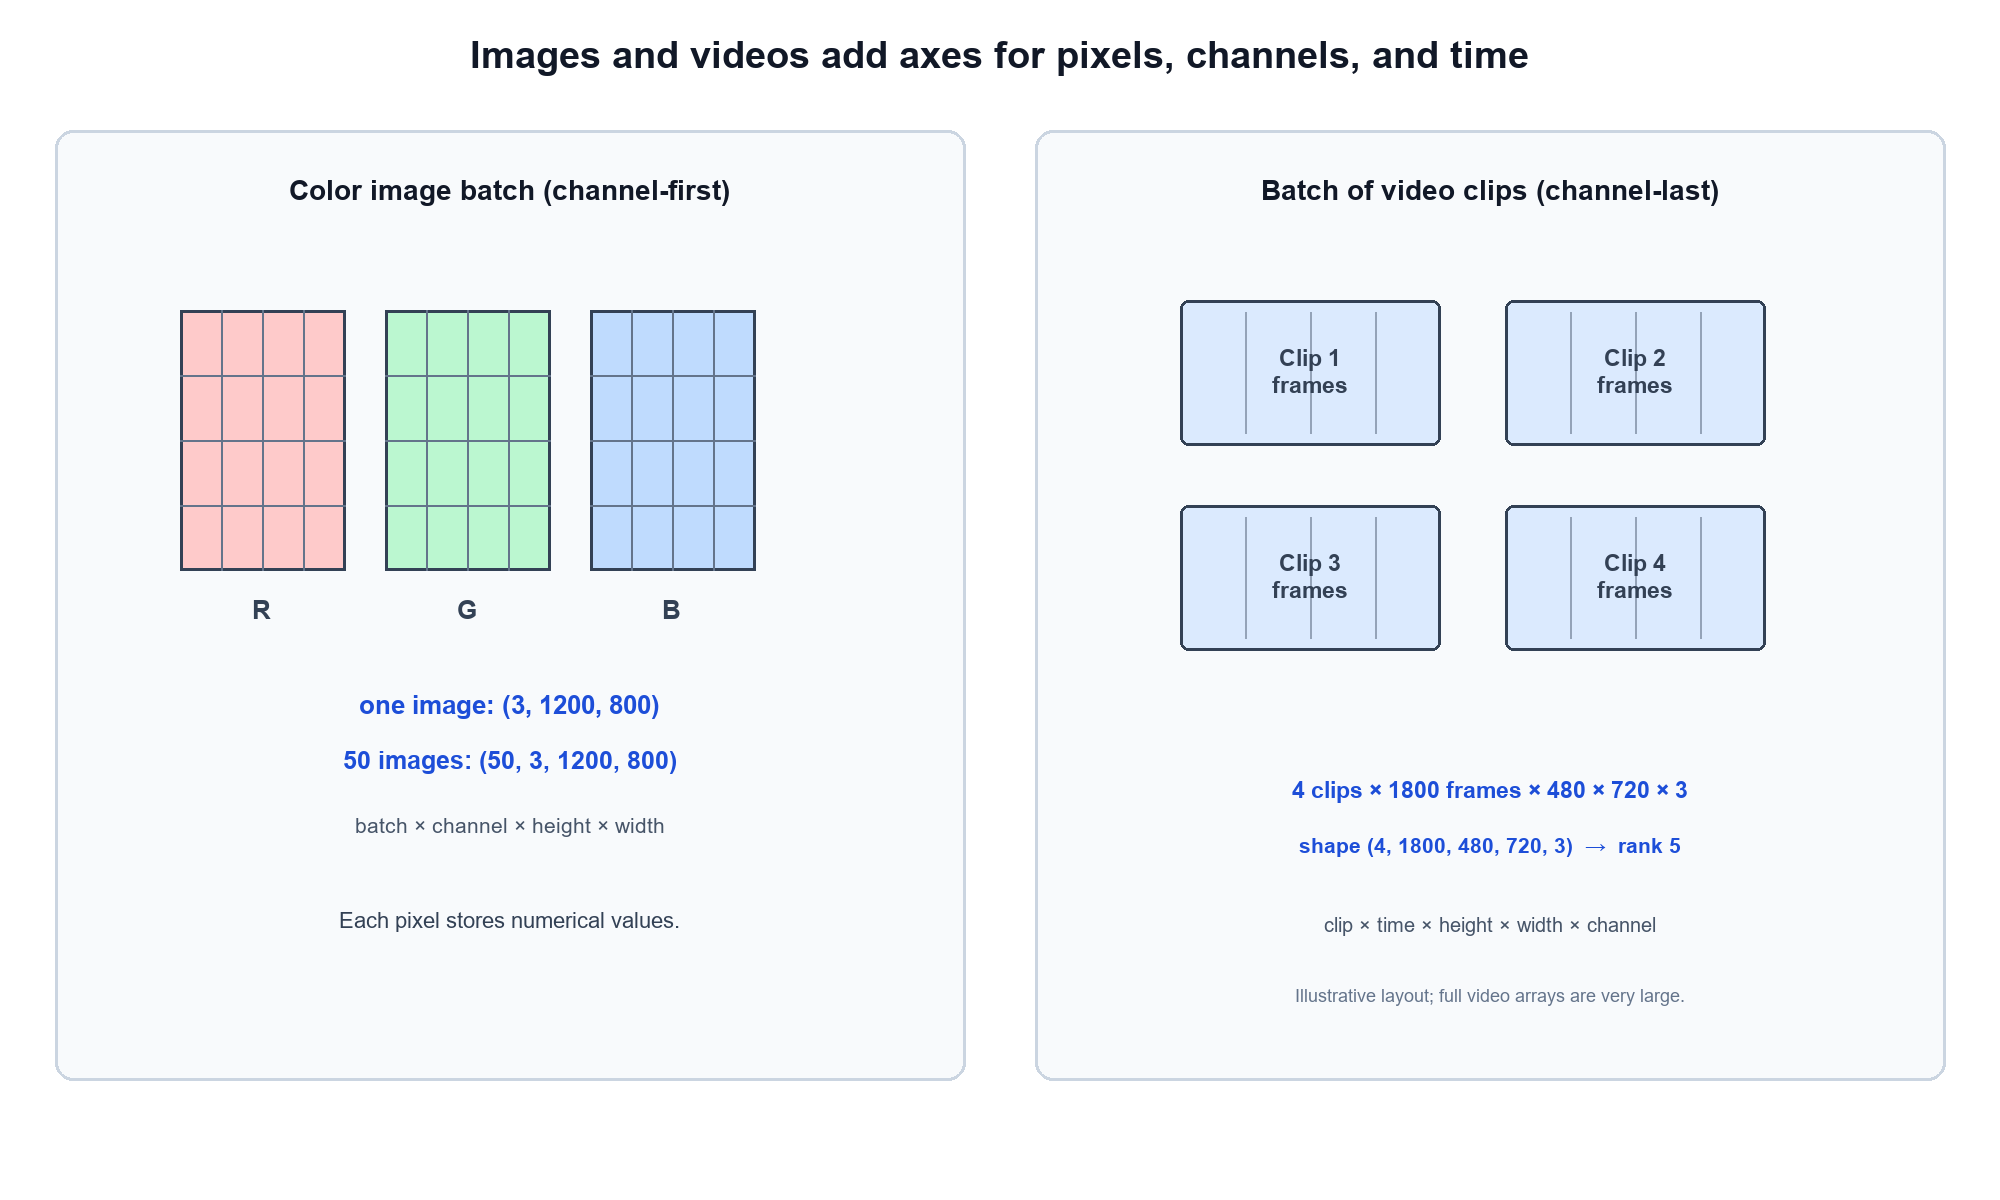

### **Estimate the storage size**

A `float32` value uses 32 bits. Multiply the number of values by 32 to get bits, then divide by 8 for bytes; further divisions by 1024 give KiB, MiB, and GiB.

$$
\text{bytes} = \text{number of values} \times \frac{\text{bits per value}}{8}
$$

In [ ]:
import math

video_shape = (4, 1800, 480, 720, 3)
value_count = math.prod(video_shape)
bits_per_value = np.dtype(np.float32).itemsize * 8
total_bits = value_count * bits_per_value
total_bytes = total_bits // 8
total_gib = total_bytes / (1024 ** 3)

print("shape:", video_shape)
print("number of values:", f"{value_count:,}")
print("storage in bits:", f"{total_bits:,}")
print("storage in bytes:", f"{total_bytes:,}")
print("storage in KiB:", f"{total_bytes / 1024:,.0f}")
print("storage in MiB:", f"{total_bytes / (1024 ** 2):,.4f}")
print("storage in GiB:", f"{total_gib:.4f}")

shape: (4, 1800, 480, 720, 3)
number of values: 7,464,960,000
storage in bits: 238,878,720,000
storage in bytes: 29,859,840,000
storage in KiB: 29,160,000
storage in MiB: 28,476.5625
storage in GiB: 27.8091


Four uncompressed clips need about **27.81 GiB** as `float32`, before any processing overhead. The handwritten calculation labels `7,464,960,000` as bits before multiplying by 32; that number is the count of values, and the multiplication gives the bit count. The notes mention MPEG, MKV, and MP4 as ways to store compressed video and reduce its size, as used by services such as YouTube.

<!-- Source transcription pages complete in source order: transcription/5.4.md, transcription/6.1.md, transcription/6.2.md, transcription/6.3.md, transcription/6.4.md -->